# Getting last dataset from HDFS

In [2]:
import os
import sys
import glob

os.environ["SPARK_HOME"] = "/usr/local/spark"
os.environ["PYSPARK_PYTHON"] = sys.executable

sys.path.insert(0, "/usr/local/spark/python")
sys.path.insert(
    0,
    glob.glob("/usr/local/spark/python/lib/py4j-*.zip")[0]
)

from pyspark.sql import SparkSession

spark = SparkSession.builder \
    .appName("CA1_NeuralNetwork") \
    .getOrCreate()

print("Spark version:", spark.version)

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
26/10/07 21:23:11 WARN Utils: Your hostname, BDSP, resolves to a loopback address: 127.0.1.1; using 10.0.2.15 instead (on interface enp0s3)
26/10/07 21:23:11 WARN Utils: Set SPARK_LOCAL_IP if you need to bind to another address
Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/10/07 21:23:12 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


Spark version: 4.1.2


In [3]:
# Load final labelled dataset

DATA_PATH = "hdfs://127.0.0.1:9000/ca1/processed/comments_labeled"

dataset = spark.read.parquet(DATA_PATH)

print("Rows:", dataset.count())
print("Columns:", len(dataset.columns))

dataset.printSchema()
dataset.show(5, truncate=80)

Rows: 108524
Columns: 11
root
 |-- comment_id: string (nullable = true)
 |-- video_id: string (nullable = true)
 |-- comment_text: string (nullable = true)
 |-- video_title: string (nullable = true)
 |-- video_description: string (nullable = true)
 |-- video_tags: array (nullable = true)
 |    |-- element: string (containsNull = true)
 |-- video_age_at_comment: double (nullable = true)
 |-- comment_hour: integer (nullable = true)
 |-- comment_weekday: integer (nullable = true)
 |-- label: integer (nullable = true)
 |-- video_category: integer (nullable = true)

+--------------------------+-----------+----------------------------------------------+------------------------------------------------------------+--------------------------------------------------------------------------------+--------------------------------------------------------------------------------+--------------------+------------+---------------+-----+--------------+
|                comment_id|   video_id|          

# EDA

In [9]:
dataset.select("comment_text", "video_title", "video_category",
               "video_age_at_comment", "comment_hour", "comment_weekday", "label") \
       .show(5, truncate=40)

print("Shape:", (dataset.count(), len(dataset.columns)))

+----------------------------------------+----------------------------------------+--------------+--------------------+------------+---------------+-----+
|                            comment_text|                             video_title|video_category|video_age_at_comment|comment_hour|comment_weekday|label|
+----------------------------------------+----------------------------------------+--------------+--------------------+------------+---------------+-----+
|You did not even dip it because I see...|Dave's Hot Chicken vs Raising Cane's:...|            19|  11.814444444444444|          19|              4|    0|
|           bang gati  ban  nya yang gede|       Jangan BERTINGKAH deh.. @mikejntk|            19|  15.036666666666667|           4|              1|    0|
|                                     OMG|              The 10-Second Time Machine|            19|  1516.0894444444446|          18|              7|    0|
|                     Hornet got violated| How Japanese Bees Cook Horn

In [10]:
dataset.printSchema()

dataset.select("video_age_at_comment", "comment_hour", "comment_weekday", "label") \
       .describe().show()

root
 |-- comment_id: string (nullable = true)
 |-- video_id: string (nullable = true)
 |-- comment_text: string (nullable = true)
 |-- video_title: string (nullable = true)
 |-- video_description: string (nullable = true)
 |-- video_tags: array (nullable = true)
 |    |-- element: string (containsNull = true)
 |-- video_age_at_comment: double (nullable = true)
 |-- comment_hour: integer (nullable = true)
 |-- comment_weekday: integer (nullable = true)
 |-- label: integer (nullable = true)
 |-- video_category: integer (nullable = true)



26/10/07 21:19:43 WARN SparkStringUtils: Truncated the string representation of a plan since it was too large. This behavior can be adjusted by setting 'spark.sql.debug.maxToStringFields'.


+-------+--------------------+-----------------+------------------+-------------------+
|summary|video_age_at_comment|     comment_hour|   comment_weekday|              label|
+-------+--------------------+-----------------+------------------+-------------------+
|  count|              108524|           108524|            108524|             108524|
|   mean|      634.8713383266|11.64079834875235| 4.049187276547123|0.04616490361579006|
| stddev|   471.2672406348328|6.639666891159533|2.0341242572765323|0.20984306289349663|
|    min|0.003055555555555...|                0|                 1|                  0|
|    max|   1981.256388888889|               23|                 7|                  1|
+-------+--------------------+-----------------+------------------+-------------------+



In [ ]:
#split the data Train, Validation, Test
video_id ile split yapiyoruz 2.modelde leakage olmamasi icin

In [3]:
from pyspark.sql import functions as F

video_ids = dataset.select("video_id").distinct()
train_videos, val_videos, test_videos = video_ids.randomSplit([0.70, 0.15, 0.15], seed=42)

train_df = dataset.join(train_videos, on="video_id", how="inner")
val_df   = dataset.join(val_videos,   on="video_id", how="inner")
test_df  = dataset.join(test_videos,  on="video_id", how="inner")

for name, part in [("Train", train_df), ("Validation", val_df), ("Test", test_df)]:
    stats = part.agg(F.count("*").alias("rows"),
                     F.countDistinct("video_id").alias("videos"),
                     F.round(F.avg("label") * 100, 2).alias("positive_%")).first()
    print(f"{name:<11} rows: {stats['rows']:>6} | videos: {stats['videos']:>3} | positive: {stats['positive_%']}%")

Train       rows:  83401 | videos: 431 | positive: 4.57%
Validation  rows:  12050 | videos:  84 | positive: 5.22%
Test        rows:  13073 | videos:  60 | positive: 4.35%


In [11]:
%pip install matplotlib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.0/11.0 MB 13.8 MB/s eta 0:00:001m14.3 MB/s eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.3/5.3 MB 11.5 MB/s eta 0:00:000:00:01m eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 9.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.9/6.9 MB 15.9 MB/s eta 0:00:000:00:010:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6/6 [matplotlib] 5/6 [matplotlib]ourpy]
Note: you may need to restart the kernel to use updated packages.


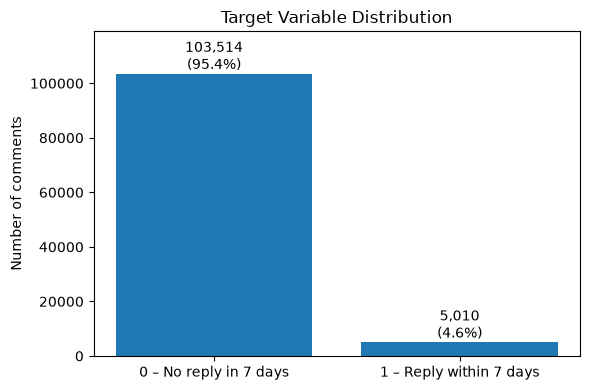

In [5]:
import matplotlib.pyplot as plt

label_counts = dataset.groupBy("label").count().orderBy("label").collect()
labels = [str(r["label"]) for r in label_counts]
counts = [r["count"] for r in label_counts]

plt.figure(figsize=(6, 4))
bars = plt.bar(labels, counts)
for bar, c in zip(bars, counts):
    plt.text(bar.get_x() + bar.get_width() / 2, c, f"{c:,}\n({c / sum(counts):.1%})",
             ha="center", va="bottom")
plt.xticks([0, 1], ["0 – No reply in 7 days", "1 – Reply within 7 days"])
plt.ylabel("Number of comments")
plt.title("Target Variable Distribution")
plt.tight_layout()
plt.ylim(0, max(counts) * 1.15)
plt.show()

In [6]:
from pyspark.sql import functions as F

text_eda = dataset.withColumn("n_words", F.size(F.split("comment_text", " ")))

length_stats = text_eda.groupBy("n_words") \
                       .agg(F.avg("label").alias("reply_rate")) \
                       .filter("n_words <= 50") \
                       .orderBy("n_words") \
                       .collect()

In [9]:
%pip install seaborn

Note: you may need to restart the kernel to use updated packages.


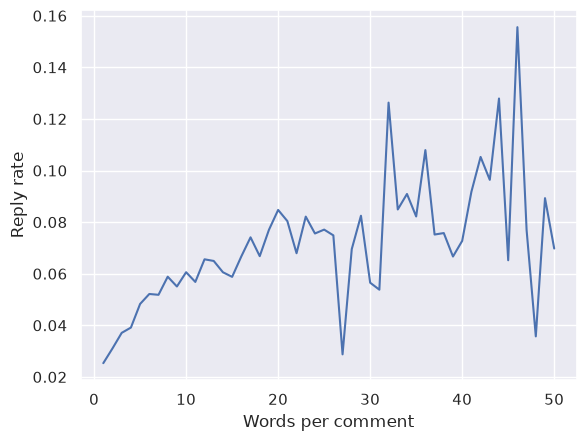

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set()
plt.xlabel('Words per comment')
plt.ylabel('Reply rate')
plt.plot([r["n_words"] for r in length_stats], [r["reply_rate"] for r in length_stats])
plt.show()

In [11]:
category_names = {1: "Film & Animation", 2: "Autos & Vehicles", 10: "Music",
                  15: "Pets & Animals", 17: "Sports", 19: "Travel & Events",
                  20: "Gaming", 22: "People & Blogs", 23: "Comedy",
                  24: "Entertainment", 25: "News & Politics", 26: "Howto & Style",
                  27: "Education", 28: "Science & Technology"}

category_stats = dataset.groupBy("video_category") \
                        .agg(F.avg("label").alias("reply_rate")) \
                        .orderBy("reply_rate") \
                        .collect()

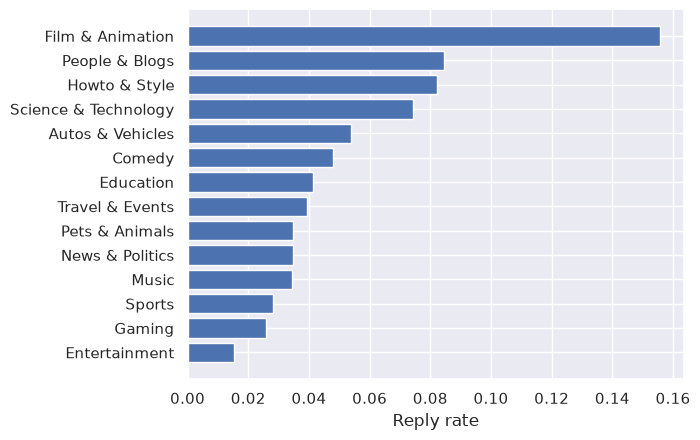

In [12]:
sns.set()
plt.xlabel('Reply rate')
plt.barh([category_names[r["video_category"]] for r in category_stats],
         [r["reply_rate"] for r in category_stats])
plt.show()

In [13]:
dataset.groupBy("video_category") \
       .agg(F.count("*").alias("comments"),
            F.countDistinct("video_id").alias("videos"),
            F.round(F.avg("label") * 100, 2).alias("reply_rate_%")) \
       .orderBy(F.desc("reply_rate_%")) \
       .show()

+--------------+--------+------+------------+
|video_category|comments|videos|reply_rate_%|
+--------------+--------+------+------------+
|             1|    2004|    40|       15.57|
|            22|    4086|    37|        8.44|
|            26|    4238|    40|        8.21|
|            28|    4125|    47|        7.42|
|             2|   13561|    48|        5.38|
|            23|   10677|    45|        4.79|
|            27|   11779|    43|        4.14|
|            19|   17460|    48|        3.92|
|            15|   15270|    49|        3.48|
|            25|   10620|    46|        3.47|
|            10|    2535|    27|        3.43|
|            17|    5757|    46|        2.81|
|            20|    3544|    37|         2.6|
|            24|    2868|    22|        1.53|
+--------------+--------+------+------------+



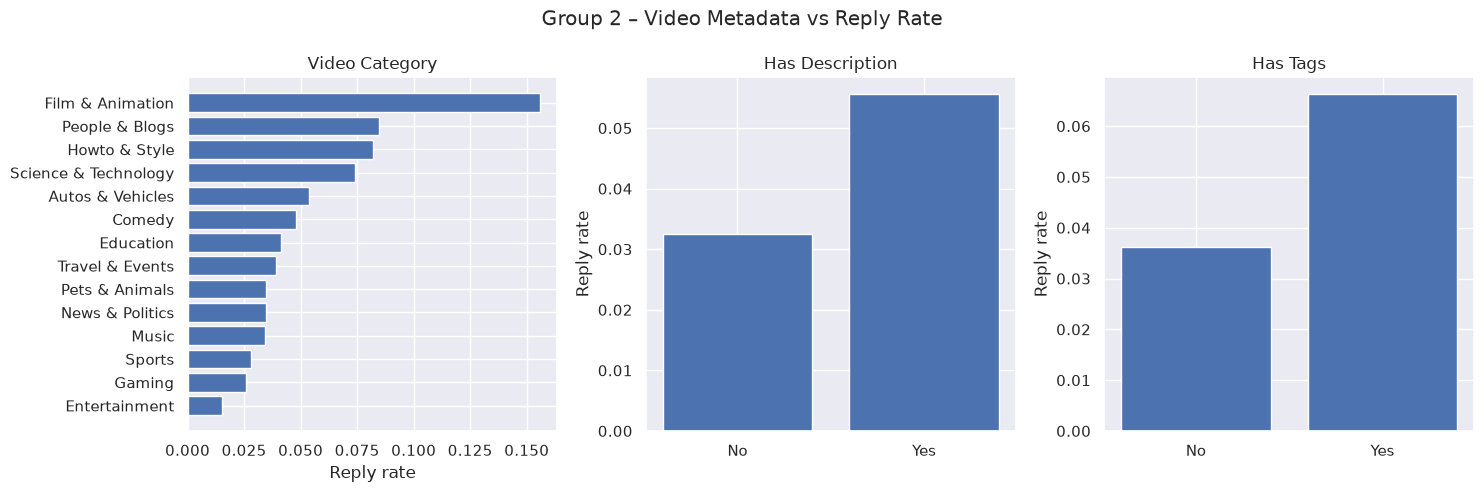

In [14]:
# Group 2 – Video Metadata
g2 = dataset.withColumn("has_description", F.trim("video_description") != "") \
            .withColumn("has_tags", F.size("video_tags") > 0)

cat  = g2.groupBy("video_category").agg(F.avg("label").alias("rate")).orderBy("rate").collect()
desc = g2.groupBy("has_description").agg(F.avg("label").alias("rate")).orderBy("has_description").collect()
tags = g2.groupBy("has_tags").agg(F.avg("label").alias("rate")).orderBy("has_tags").collect()

sns.set()
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].barh([category_names[r["video_category"]] for r in cat], [r["rate"] for r in cat])
axes[0].set_title("Video Category")

axes[1].bar(["No", "Yes"], [r["rate"] for r in desc])
axes[1].set_title("Has Description")

axes[2].bar(["No", "Yes"], [r["rate"] for r in tags])
axes[2].set_title("Has Tags")

for ax in axes:
    ax.set_xlabel("Reply rate") if ax == axes[0] else ax.set_ylabel("Reply rate")

fig.suptitle("Group 2 – Video Metadata vs Reply Rate")
plt.tight_layout()
plt.show()